# BQ07 — Capability của thiết bị có còn liên quan đến churn sau điều chỉnh?

## Câu hỏi kinh doanh
Sau khi kiểm soát **tuổi thiết bị hiện tại** và **thời gian sử dụng dịch vụ** dưới dạng liên tục, `HandsetWebCapable` còn tạo ra chênh lệch churn đủ lớn, đủ chắc chắn và đủ độ phủ để nhà mạng hành động hay không?

## Quyết định cần đưa ra
- **KEEP:** giữ làm tín hiệu hành động và kiểm chứng bằng thử nghiệm giữ chân.
- **CONTEXT ONLY:** chỉ dùng làm bối cảnh/reason code phụ, không tạo chính sách riêng.
- **REMOVE:** loại khỏi câu chuyện chính sách nếu chênh lệch yếu hoặc không ổn định.

## Phạm vi
Chỉ dùng `Churn`, `CurrentEquipmentDays`, `HandsetWebCapable`, `MonthsInService` trong bộ feature đã chốt. **Không tạo `EquipmentAgeBand`, không tạo `TenureBand`, không chia nhóm tuổi thiết bị.**

> `HandsetWebCapable` là metadata về capability kỹ thuật của thiết bị đối với dịch vụ web/data; không có nghĩa nhà mạng có hay không có kênh hỗ trợ web, cũng không tự chứng minh lỗi mạng hoặc nguyên nhân churn.


In [1]:
BQ07_VERSION = 'BQ07_ANALYSIS_FIRST_CONTINUOUS_V4'
print(f'Đang chạy: {BQ07_VERSION}')

from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display, Markdown
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import SplineTransformer

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_columns', 100)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
plt.style.use('seaborn-v0_8-whitegrid')

SEED = 42
N_KNOTS = 5
BOOTSTRAP_REPEATS = 100
STANDARDIZATION_N = 800
AGE_GRID_POINTS = 70
MIN_BUSINESS_EFFECT = 0.02
MIN_REACH = 0.05
MIN_DIRECTION_STABILITY = 0.80
rng = np.random.default_rng(SEED)


Đang chạy: BQ07_ANALYSIS_FIRST_CONTINUOUS_V4


## 1. Khóa cohort và kiểm tra dữ liệu

Chỉ loại các dòng không thể sử dụng cho BQ07. Hai biến thời gian vẫn được giữ nguyên dạng liên tục.


In [2]:
DATA_CANDIDATES = [Path('../data/cell2cell_complete_cases.csv'), Path('data/cell2cell_complete_cases.csv')]
DATA_PATH = next((path for path in DATA_CANDIDATES if path.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError('Không tìm thấy data/cell2cell_complete_cases.csv')

raw = pd.read_csv(DATA_PATH)
required_columns = ['Churn', 'CurrentEquipmentDays', 'HandsetWebCapable', 'MonthsInService']
missing_columns = sorted(set(required_columns) - set(raw.columns))
if missing_columns:
    raise KeyError(f'Thiếu cột bắt buộc: {missing_columns}')

def normalize_binary(series):
    values = series.astype('string').str.strip().str.lower()
    mapping = {'yes': 1, 'y': 1, 'true': 1, '1': 1, '1.0': 1,
               'no': 0, 'n': 0, 'false': 0, '0': 0, '0.0': 0}
    return values.map(mapping)

work = raw[required_columns].copy()
work['Churn_bin'] = normalize_binary(work['Churn'])
work['Capability_bin'] = normalize_binary(work['HandsetWebCapable'])
work['CurrentEquipmentDays'] = pd.to_numeric(work['CurrentEquipmentDays'], errors='coerce')
work['MonthsInService'] = pd.to_numeric(work['MonthsInService'], errors='coerce')

valid_mask = (
    work[['Churn_bin', 'Capability_bin', 'CurrentEquipmentDays', 'MonthsInService']].notna().all(axis=1)
    & work['CurrentEquipmentDays'].ge(0)
    & work['MonthsInService'].ge(0)
)
bq07 = work.loc[valid_mask].copy()
bq07[['Churn_bin', 'Capability_bin']] = bq07[['Churn_bin', 'Capability_bin']].astype(int)

qa = pd.DataFrame({
    'Chỉ tiêu': ['Tổng đầu vào', 'Dòng bị loại', 'Cohort BQ07', 'Tỷ lệ giữ lại'],
    'Giá trị': [len(work), int((~valid_mask).sum()), len(bq07), valid_mask.mean()],
})
display(qa)
display(bq07[['CurrentEquipmentDays', 'MonthsInService']].describe(percentiles=[.01, .10, .50, .90, .99]).T)
print('Xác nhận: không tạo band cho tuổi thiết bị hoặc tenure.')


,Chỉ tiêu,Giá trị
0,Tổng đầu vào,"49,752.0000"
1,Dòng bị loại,74.0000
2,Cohort BQ07,"49,678.0000"
3,Tỷ lệ giữ lại,0.9985


,count,mean,std,min,1%,10%,50%,90%,99%,max
CurrentEquipmentDays,"49,678.0000",380.5905,252.0455,0.0000,9.0000,90.0000,330.0000,731.0000,"1,138.0000","1,812.0000"
MonthsInService,"49,678.0000",18.7275,9.7374,6.0000,6.0000,8.0000,16.0000,33.0000,49.0000,61.0000


Xác nhận: không tạo band cho tuổi thiết bị hoặc tenure.


## 2. Bức tranh ban đầu: rủi ro thô và độ phủ

Bảng này cho biết quy mô, số churner và churn rate của hai trạng thái capability. Đây chưa phải kết luận vì cơ cấu tuổi thiết bị và tenure có thể khác nhau.


In [3]:
capability_label = {
    1: 'Thiết bị có capability web/data',
    0: 'Thiết bị không có capability web/data',
}
raw_summary = (
    bq07.groupby('Capability_bin', observed=True)
        .agg(Customers=('Churn_bin', 'size'),
             Churners=('Churn_bin', 'sum'),
             ChurnRate=('Churn_bin', 'mean'),
             MedianEquipmentDays=('CurrentEquipmentDays', 'median'),
             MedianTenureMonths=('MonthsInService', 'median'))
        .reset_index()
)
raw_summary['Trạng thái thiết bị'] = raw_summary['Capability_bin'].map(capability_label)
raw_summary['CustomerShare'] = raw_summary['Customers'] / raw_summary['Customers'].sum()
raw_rate = raw_summary.set_index('Capability_bin')['ChurnRate']
raw_gap = raw_rate.loc[0] - raw_rate.loc[1]
display(raw_summary[['Trạng thái thiết bị', 'Customers', 'CustomerShare', 'Churners',
                     'ChurnRate', 'MedianEquipmentDays', 'MedianTenureMonths']])
print(f'Chênh lệch churn thô (không capability − có capability): {raw_gap:+.2%}')


,Trạng thái thiết bị,Customers,CustomerShare,Churners,ChurnRate,MedianEquipmentDays,MedianTenureMonths
0,Thiết bị không có capability web/data,4838,0.0974,1803,0.3727,677.0000,25.0000
1,Thiết bị có capability web/data,44840,0.9026,12428,0.2772,314.0000,15.0000


Chênh lệch churn thô (không capability − có capability): +9.55%


## 3. Bằng chứng chính: đường churn liên tục đã điều chỉnh

Spline logistic chỉ dùng để điều chỉnh hai biến thời gian liên tục; đây không phải bài toán chọn mô hình dự đoán. Mô hình cho phép quan hệ tuổi thiết bị–churn có hình cong và khác nhau theo capability.


In [4]:
def fit_adjustment_model(data, n_knots=N_KNOTS):
    age_spline = SplineTransformer(n_knots=n_knots, degree=3, knots='quantile',
                                    include_bias=False, extrapolation='linear')
    tenure_spline = SplineTransformer(n_knots=n_knots, degree=3, knots='quantile',
                                       include_bias=False, extrapolation='linear')
    age_basis = age_spline.fit_transform(data[['CurrentEquipmentDays']])
    tenure_basis = tenure_spline.fit_transform(data[['MonthsInService']])
    capability = data['Capability_bin'].to_numpy(dtype=float).reshape(-1, 1)
    design = np.column_stack([capability, age_basis, tenure_basis, age_basis * capability])
    model = LogisticRegression(C=100.0, solver='lbfgs', max_iter=2000, random_state=SEED)
    model.fit(design, data['Churn_bin'].to_numpy())
    return model, age_spline, tenure_spline

def make_design(frame, age_spline, tenure_spline, capability_status):
    age_basis = age_spline.transform(frame[['CurrentEquipmentDays']])
    tenure_basis = tenure_spline.transform(frame[['MonthsInService']])
    capability = np.full((len(frame), 1), float(capability_status))
    return np.column_stack([capability, age_basis, tenure_basis, age_basis * capability])

def standardized_probability(model, age_spline, tenure_spline, frame, capability_status):
    design = make_design(frame, age_spline, tenure_spline, capability_status)
    return model.predict_proba(design)[:, 1].mean()

def predict_curve(model, age_spline, tenure_spline, ages, reference_tenure, status):
    result = []
    for age in ages:
        frame = pd.DataFrame({'CurrentEquipmentDays': np.full(len(reference_tenure), age),
                              'MonthsInService': reference_tenure})
        result.append(standardized_probability(model, age_spline, tenure_spline, frame, status))
    return np.asarray(result)

reference = (bq07[['CurrentEquipmentDays', 'MonthsInService']]
             .sample(n=min(STANDARDIZATION_N, len(bq07)), random_state=SEED)
             .reset_index(drop=True))
age_low, age_high = bq07['CurrentEquipmentDays'].quantile([.02, .98])
age_grid = np.linspace(age_low, age_high, AGE_GRID_POINTS)

main_model, main_age_spline, main_tenure_spline = fit_adjustment_model(bq07)
adjusted_probability, adjusted_curve = {}, {}
for status in [0, 1]:
    adjusted_probability[status] = standardized_probability(
        main_model, main_age_spline, main_tenure_spline, reference, status)
    adjusted_curve[status] = predict_curve(
        main_model, main_age_spline, main_tenure_spline, age_grid,
        reference['MonthsInService'].to_numpy(), status)

adjusted_gap = adjusted_probability[0] - adjusted_probability[1]
curve_gap = adjusted_curve[0] - adjusted_curve[1]
print(f'Chênh lệch churn đã điều chỉnh (không capability − có capability): {adjusted_gap:+.2%}')


Chênh lệch churn đã điều chỉnh (không capability − có capability): +8.00%


## 4. Độ chắc chắn bằng bootstrap

Bootstrap lặp lại toàn bộ phép điều chỉnh trên nhiều mẫu khách hàng để tạo khoảng tin cậy, thay vì kết luận từ một đường duy nhất.


In [5]:
bootstrap_overall_gap = []
bootstrap_curve = {0: [], 1: []}

for repeat in range(BOOTSTRAP_REPEATS):
    bootstrap_index = rng.integers(0, len(bq07), size=len(bq07))
    sample = bq07.iloc[bootstrap_index].reset_index(drop=True)
    model_b, age_spline_b, tenure_spline_b = fit_adjustment_model(sample)
    probability_b = {}
    for status in [0, 1]:
        probability_b[status] = standardized_probability(
            model_b, age_spline_b, tenure_spline_b, reference, status)
        bootstrap_curve[status].append(predict_curve(
            model_b, age_spline_b, tenure_spline_b, age_grid,
            reference['MonthsInService'].to_numpy(), status))
    bootstrap_overall_gap.append(probability_b[0] - probability_b[1])

bootstrap_overall_gap = np.asarray(bootstrap_overall_gap)
bootstrap_curve = {status: np.vstack(values) for status, values in bootstrap_curve.items()}
bootstrap_curve_gap = bootstrap_curve[0] - bootstrap_curve[1]
overall_gap_ci = np.quantile(bootstrap_overall_gap, [.025, .975])
curve_ci = {status: np.quantile(values, [.025, .975], axis=0)
            for status, values in bootstrap_curve.items()}
curve_gap_ci = np.quantile(bootstrap_curve_gap, [.025, .975], axis=0)
direction_stability = np.mean(np.sign(bootstrap_overall_gap) == np.sign(adjusted_gap))
curve_supported_share = np.mean((curve_gap_ci[0] > 0) | (curve_gap_ci[1] < 0))


## 5. Chuyển bằng chứng thành quyết định kinh doanh

Tín hiệu chỉ đáng đưa vào chính sách khi đồng thời có **risk** đủ lớn, **certainty** đủ chắc chắn và **reach** đủ rộng.


In [6]:
high_risk_status = 0 if adjusted_gap >= 0 else 1
low_risk_status = 1 - high_risk_status
high_risk_mask = bq07['Capability_bin'].eq(high_risk_status)
reach = high_risk_mask.mean()
customers_reached = int(high_risk_mask.sum())
churners_reached = int(bq07.loc[high_risk_mask, 'Churn_bin'].sum())
absolute_effect = abs(adjusted_gap)
ci_excludes_zero = (overall_gap_ci[0] > 0) or (overall_gap_ci[1] < 0)

effect_is_meaningful = absolute_effect >= MIN_BUSINESS_EFFECT
effect_is_stable = ci_excludes_zero and direction_stability >= MIN_DIRECTION_STABILITY
reach_is_sufficient = reach >= MIN_REACH

if effect_is_meaningful and effect_is_stable and reach_is_sufficient:
    decision = 'KEEP — giữ làm giả thuyết hành động'
    policy = ('Thử nghiệm kiểm tra tương thích thiết bị–dịch vụ data, hỗ trợ cấu hình và '
              'hướng dẫn chủ động; đo uplift bằng treatment/control.')
elif effect_is_meaningful or effect_is_stable:
    decision = 'CONTEXT ONLY — chỉ dùng làm reason code phụ'
    policy = ('Không tạo chiến dịch riêng; chỉ dùng tín hiệu này làm bối cảnh khi khách '
              'đồng thời có churn risk cao từ các bằng chứng khác.')
else:
    decision = 'REMOVE — loại khỏi câu chuyện chính sách'
    policy = ('Không nhắm mục tiêu hoặc đưa ưu đãi dựa trên capability vì bằng chứng '
              'không đủ mạnh sau điều chỉnh.')

evidence = pd.DataFrame({
    'Bằng chứng': ['Adjusted churn — nhóm risk cao', 'Adjusted churn — nhóm risk thấp',
                   'Chênh lệch tuyệt đối', '95% CI của No − Yes',
                   'Độ ổn định hướng bootstrap', 'Tỷ lệ miền tuổi có CI khác 0',
                   'Độ phủ nhóm risk cao', 'Số khách nhóm risk cao',
                   'Số churner nhóm risk cao'],
    'Kết quả': [f'{adjusted_probability[high_risk_status]:.2%}',
                f'{adjusted_probability[low_risk_status]:.2%}',
                f'{absolute_effect:.2%}',
                f'[{overall_gap_ci[0]:+.2%}; {overall_gap_ci[1]:+.2%}]',
                f'{direction_stability:.1%}', f'{curve_supported_share:.1%}',
                f'{reach:.1%}', f'{customers_reached:,}', f'{churners_reached:,}'],
})
display(evidence)
print(f'QUYẾT ĐỊNH BQ07: {decision}')


,Bằng chứng,Kết quả
0,Adjusted churn — nhóm risk cao,35.92%
1,Adjusted churn — nhóm risk thấp,27.92%
2,Chênh lệch tuyệt đối,8.00%
3,95% CI của No − Yes,[+6.00%; +9.77%]
4,Độ ổn định hướng bootstrap,100.0%
5,Tỷ lệ miền tuổi có CI khác 0,91.4%
6,Độ phủ nhóm risk cao,9.7%
7,Số khách nhóm risk cao,"4,838"
8,Số churner nhóm risk cao,"1,803"


QUYẾT ĐỊNH BQ07: KEEP — giữ làm giả thuyết hành động


## 6. C07 — Biểu đồ kể chuyện chính

Panel trái cho thấy churn đã điều chỉnh theo tuổi thiết bị liên tục. Panel phải cho thấy chênh lệch `không capability − có capability`; đường 0 nghĩa là không còn khác biệt. Chỉ hiển thị P02–P98 để tránh ngoại suy, không phải chia band.


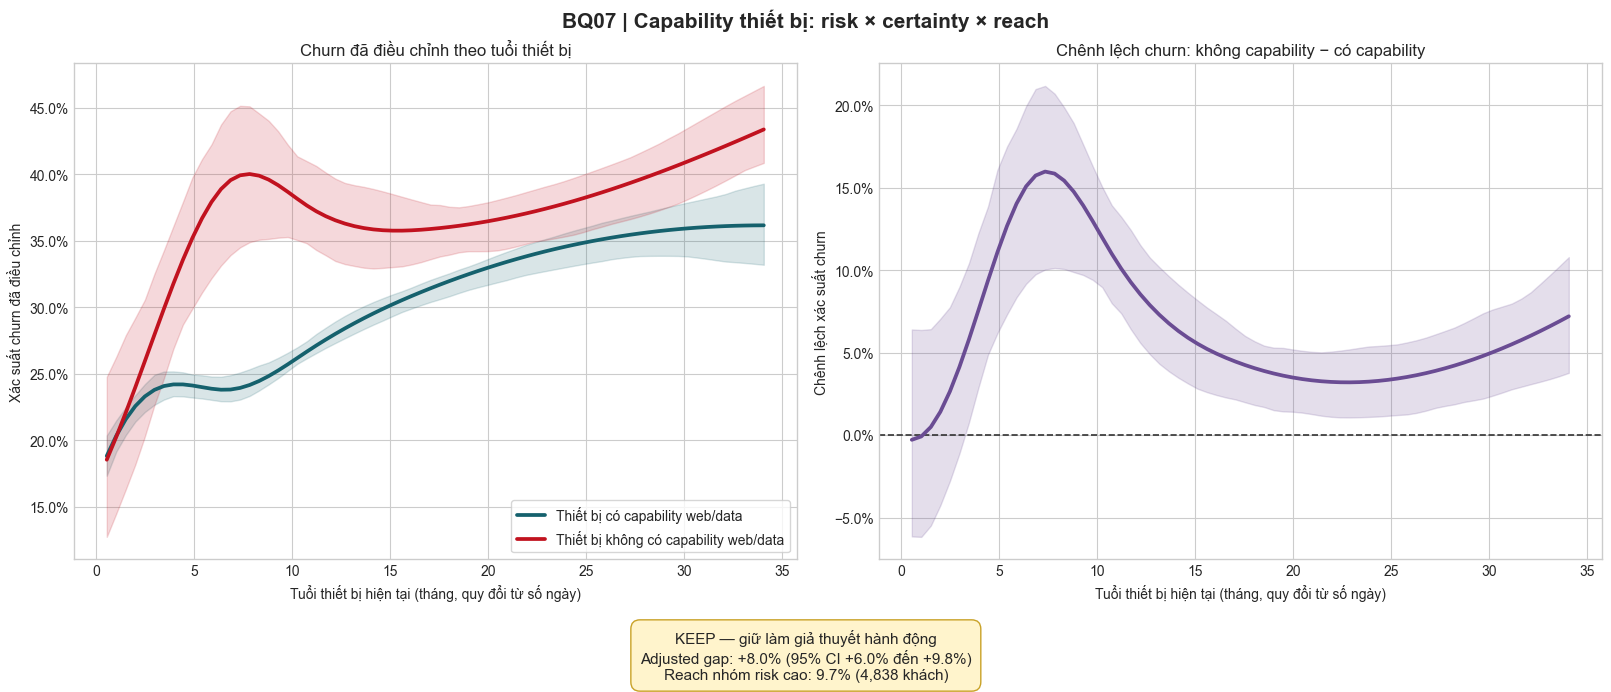

In [7]:
colors = {1: '#15616D', 0: '#C1121F'}
age_months = age_grid / 30.44
fig, (ax_curve, ax_gap) = plt.subplots(1, 2, figsize=(16, 6), constrained_layout=True)

for status in [1, 0]:
    ax_curve.plot(age_months, adjusted_curve[status], color=colors[status],
                  linewidth=2.7, label=capability_label[status])
    ax_curve.fill_between(age_months, curve_ci[status][0], curve_ci[status][1],
                          color=colors[status], alpha=0.16)
ax_curve.set(title='Churn đã điều chỉnh theo tuổi thiết bị',
             xlabel='Tuổi thiết bị hiện tại (tháng, quy đổi từ số ngày)',
             ylabel='Xác suất churn đã điều chỉnh')
ax_curve.yaxis.set_major_formatter(PercentFormatter(1))
ax_curve.legend(frameon=True)

ax_gap.axhline(0, color='#333333', linestyle='--', linewidth=1.2)
ax_gap.plot(age_months, curve_gap, color='#6A4C93', linewidth=2.7)
ax_gap.fill_between(age_months, curve_gap_ci[0], curve_gap_ci[1],
                    color='#6A4C93', alpha=0.18)
ax_gap.set(title='Chênh lệch churn: không capability − có capability',
           xlabel='Tuổi thiết bị hiện tại (tháng, quy đổi từ số ngày)',
           ylabel='Chênh lệch xác suất churn')
ax_gap.yaxis.set_major_formatter(PercentFormatter(1))

decision_box = (f'{decision}\n'
                f'Adjusted gap: {adjusted_gap:+.1%} '
                f'(95% CI {overall_gap_ci[0]:+.1%} đến {overall_gap_ci[1]:+.1%})\n'
                f'Reach nhóm risk cao: {reach:.1%} ({customers_reached:,} khách)')
fig.suptitle('BQ07 | Capability thiết bị: risk × certainty × reach',
             fontsize=15, fontweight='bold')
fig.text(0.5, -0.04, decision_box, ha='center', va='top', fontsize=11,
         bbox=dict(boxstyle='round,pad=0.6', facecolor='#FFF4CC', edgecolor='#C9A227'))
plt.show()


## 7. Kết luận tự động để đưa vào báo cáo

Cell dưới đây tạo đoạn kết luận có số liệu, tránh nhận định chung chung.


In [8]:
high_risk_label = capability_label[high_risk_status].lower()
story = f'''
### Insight BQ07

Sau khi đặt hai trạng thái thiết bị trên cùng phân phối tuổi thiết bị và thời gian sử dụng, 
nhóm **{high_risk_label}** có xác suất churn ước tính **{adjusted_probability[high_risk_status]:.1%}**, 
so với **{adjusted_probability[low_risk_status]:.1%}** ở trạng thái còn lại. Chênh lệch tuyệt đối là 
**{absolute_effect:.1%}**; khoảng tin cậy bootstrap cho No − Yes từ 
**{overall_gap_ci[0]:+.1%} đến {overall_gap_ci[1]:+.1%}**. Nhóm risk cao chiếm **{reach:.1%}** cohort, 
tương đương **{customers_reached:,} khách**, trong đó có **{churners_reached:,} churner**.

**Quyết định:** {decision}.  
**Hành động đề xuất:** {policy}

Đây là bằng chứng quan sát sau điều chỉnh, không phải bằng chứng capability gây churn. 
Không diễn giải `HandsetWebCapable = No` thành lỗi mạng hoặc lý do tự động bán/đổi điện thoại.
'''
display(Markdown(story))



### Insight BQ07

Sau khi đặt hai trạng thái thiết bị trên cùng phân phối tuổi thiết bị và thời gian sử dụng, 
nhóm **thiết bị không có capability web/data** có xác suất churn ước tính **35.9%**, 
so với **27.9%** ở trạng thái còn lại. Chênh lệch tuyệt đối là 
**8.0%**; khoảng tin cậy bootstrap cho No − Yes từ 
**+6.0% đến +9.8%**. Nhóm risk cao chiếm **9.7%** cohort, 
tương đương **4,838 khách**, trong đó có **1,803 churner**.

**Quyết định:** KEEP — giữ làm giả thuyết hành động.  
**Hành động đề xuất:** Thử nghiệm kiểm tra tương thích thiết bị–dịch vụ data, hỗ trợ cấu hình và hướng dẫn chủ động; đo uplift bằng treatment/control.

Đây là bằng chứng quan sát sau điều chỉnh, không phải bằng chứng capability gây churn. 
Không diễn giải `HandsetWebCapable = No` thành lỗi mạng hoặc lý do tự động bán/đổi điện thoại.


## Nối BQ07 vào storytelling chung

1. BQ06 mô tả quan hệ giữa tuổi thiết bị và churn.
2. BQ07 kiểm tra capability còn tạo chênh lệch sau khi tuổi thiết bị và tenure đã được điều chỉnh liên tục.
3. Nếu **KEEP**, capability trở thành reason-code candidate cho thử nghiệm hỗ trợ tương thích/cấu hình dịch vụ data.
4. Nếu **CONTEXT ONLY**, tín hiệu chỉ bổ sung bối cảnh cho khách đã có churn risk cao.
5. Nếu **REMOVE**, chính sách thiết bị dựa trên BQ06, không dựa trên capability.
